In [5]:
import librosa
import librosa.display
import soundfile as sf
import pretty_midi
import museval
from scipy.io import wavfile

from musicProcessing import MusicProcessingProvider as mp

from tqdm import tqdm
import os
import numpy as np

from pandas import DataFrame
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def get_source_activity(midi_path, sr, hop_length, max_frames):
    # loads individual source midi and returns a np.array with all the active time frame indexes
    pm = pretty_midi.PrettyMIDI(midi_path)
    active_frames = np.asarray([], dtype=int)
    for instrument in pm.instruments:
        for note in instrument.notes:
            start_frame = np.floor(note.start * sr / hop_length).astype(int)
            end_frame = np.floor(note.end * sr / hop_length).astype(int)
            active_frames = np.union1d(active_frames, np.arange(start_frame, end_frame))
    # clip to max_frames
    active_frames = active_frames[active_frames < max_frames]
    return active_frames

In [3]:
def eval_full_track(estimated_audios, reference_audios, win_length, hop_length):
    """
    estimated_audios: list of 1D arrays of the estimated stems
    reference_audios: list of 1D arrays of the reference stems
    """
    min_len = min(min(len(a) for a in estimated_audios), min(len(r) for r in reference_audios))
    
    # 1. Add a microscopic time-domain noise floor to prevent absolute silence
    # 1e-7 is completely inaudible but stops 0/0 division errors in bss_eval
    est_list = []
    for a in estimated_audios:
        signal = a[:min_len].copy().astype(np.float32)
        noise = 1e-7 * np.random.randn(*signal.shape)
        est_list.append((signal + noise).reshape(-1, 1))
        
    ref_list = []
    for r in reference_audios:
        signal = r[:min_len].copy().astype(np.float32)
        noise = 1e-7 * np.random.randn(*signal.shape)
        ref_list.append((signal + noise).reshape(-1, 1))
    
    # 2. Stack into 3D matrices: (n_sources, n_samples, 1)
    est_matrix = np.stack(est_list, axis=0)
    ref_matrix = np.stack(ref_list, axis=0)

    # 3. Run evaluate using museval
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        sdr, isr, sir, sar = museval.evaluate(ref_matrix, est_matrix, win=win_length, hop=hop_length)
    
    # 4. Use nanmedian (or nanmean) to safely bypass any residual edge-case NaNs
    sdr_scalars = np.nanmedian(sdr, axis=1)
    sir_scalars = np.nanmedian(sir, axis=1)
    sar_scalars = np.nanmedian(sar, axis=1)
    
    return sdr_scalars, sir_scalars, sar_scalars

In [3]:
baby_slakh_path = "/home/bordduk69/Nextcloud/NTNU/10. Vår2026/Master/Code/babyslakh_16k/"
results_path = "/home/bordduk69/Nextcloud/NTNU/10. Vår2026/Master/Code/REBEAT/experiments/results/exp3/"
os.makedirs(results_path, exist_ok=True)
repetiveness_scores_path = "/home/bordduk69/Nextcloud/NTNU/10. Vår2026/Master/Code/REBEAT/repetiveness.csv"

repetiveness_df = pd.read_csv(repetiveness_scores_path)
#drop all cols but track_id, stem_id and score
repetiveness_df = repetiveness_df[["track_id", "stem_id", "score"]]
# sort by track name then by source stem
repetiveness_df = repetiveness_df.sort_values(by=["track_id", "stem_id"])

nfft = 2048
win_length = 2048
hop_length = 512
window_type = "hann"

In [5]:
tracks = os.listdir(baby_slakh_path)
tracks.sort()

results = DataFrame(columns=["track_id", "stem_id", "sdr", "sir", "sar", "repetiveness_score"])

for track in tqdm(tracks):
    track_path = os.path.join(baby_slakh_path, track)
    
    # create folder for results if it doesn't exist
    track_results_path = os.path.join(results_path, track)
    os.makedirs(track_results_path, exist_ok=True)

    mixture_path = os.path.join(track_path, "mix.wav")
    stems_path = os.path.join(track_path, "stems")
    midi_path = os.path.join(track_path, "MIDI")
    
    music_processor = mp(path=mixture_path, duration=None, nfft=nfft, hop_length=hop_length, win_length=win_length, window_type=window_type)
    
    track_est_audios = []
    track_ref_audios = []
    track_stem_names = []
    
    # Get all clean wav files and sort them to guarantee a predictable sequence
    wav_files = sorted([f for f in os.listdir(stems_path) if f.endswith(".wav") and not f.startswith(".")])
    
    for wav_file in wav_files:
        stem_name = wav_file.replace(".wav", "")
        midi_file = f"{stem_name}.mid"
        
        stem_wave_path = os.path.join(stems_path, wav_file)
        stem_midi_path = os.path.join(midi_path, midi_file)
        
        # Guard against a missing MIDI file
        if not os.path.exists(stem_midi_path):
            print(f"Warning: Missing MIDI file for {stem_wave_path}. Skipping.")
            continue
            
        active_frames = get_source_activity(stem_midi_path, music_processor.sr, hop_length, music_processor.magnitude.shape[1])
        
        if len(active_frames) == 0:
            # Instead of crashing your entire pipeline, log it and move to the next stem
            print(f"Skipping {stem_name} in {track}: No active frames found in MIDI.")
            continue
        
        # perform median filtering on the active frames
        W = music_processor.median_filter(frames=active_frames)
        mask = music_processor.calc_mask(W)

        source_data = music_processor.apply_mask(music_processor.stft, mask)
        source_data = music_processor.calc_iSTFT(source_data, hop_length=hop_length, win_length=win_length, window_type=window_type)
        
        # save the estimated source
        estimated_path = os.path.join(track_results_path, f"{stem_name}_estimated.wav")
        sf.write(estimated_path, source_data, music_processor.sr)
        
        # Load and append to our evaluation batch
        ref_audio, _ = sf.read(stem_wave_path)
        
        track_est_audios.append(source_data)
        track_ref_audios.append(ref_audio)
        track_stem_names.append(stem_name)

    # --- Run evaluation once per track ---
    # Only run if we actually successfully processed stems for this track
    if track_est_audios:
        track_sdrs, track_sirs, track_sars = eval_full_track(track_est_audios, track_ref_audios, win_length, hop_length)

        # --- Store results into your dataframe ---
        for idx, stem_name in enumerate(track_stem_names):
            sdr_val = track_sdrs[idx]
            sir_val = track_sirs[idx]
            sar_val = track_sars[idx]
            
            # Get your repetiveness score...
            repetiveness_score = repetiveness_df[(repetiveness_df["track_id"] == track) & (repetiveness_df["stem_id"] == stem_name)]["score"].values
            repetiveness_score = repetiveness_score[0] if len(repetiveness_score) > 0 else None
            
            row = DataFrame({
                "track_id": [track],
                "stem_id": [stem_name],
                "sdr": [sdr_val],
                "sir": [sir_val],
                "sar": [sar_val],
                "repetiveness_score": [repetiveness_score]
            })
            results = pd.concat([results, row], ignore_index=True)
results.to_csv(os.path.join(results_path, "evaluation_results.csv"), index=False)

  0%|          | 0/20 [00:00<?, ?it/s]/home/bordduk69/Nextcloud/NTNU/10. Vår2026/Master/Code/REBEAT/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 20/20 [48:09<00:00, 144.47s/it]


In [6]:
results_df = pd.read_csv(os.path.join(results_path, "evaluation_results.csv"))

# means and standard deviations for each metric
mean_sdr = results_df["sdr"].mean()
std_sdr = results_df["sdr"].std()
mean_sir = results_df["sir"].mean()
std_sir = results_df["sir"].std()
mean_sar = results_df["sar"].mean()
std_sar = results_df["sar"].std()

print(f"Mean SDR: {mean_sdr:.2f} dB, Std SDR: {std_sdr:.2f} dB")
print(f"Mean SIR: {mean_sir:.2f} dB, Std SIR: {std_sir:.2f} dB")
print(f"Mean SAR: {mean_sar:.2f} dB, Std SAR: {std_sar:.2f} dB")

Mean SDR: -1.89 dB, Std SDR: 1.58 dB
Mean SIR: -40.29 dB, Std SIR: 34.79 dB
Mean SAR: 0.71 dB, Std SAR: 1.49 dB


Pearson correlation coefficient: 0.0265


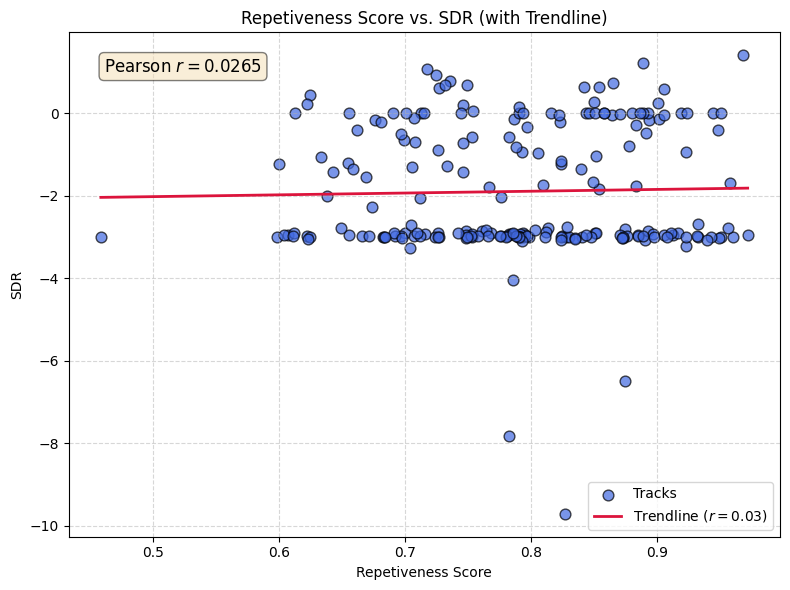

In [7]:
# plot scatter plot of repetiveness score vs SDR
correlation = results_df["repetiveness_score"].corr(results_df["sdr"])
print(f"Pearson correlation coefficient: {correlation:.4f}")

m, b = np.polyfit(results_df["repetiveness_score"], results_df["sdr"], 1)

x_line = np.linspace(results_df["repetiveness_score"].min(), results_df["repetiveness_score"].max(), 100)
y_line = m * x_line + b

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    results_df["repetiveness_score"], 
    results_df["sdr"], 
    color='royalblue', 
    alpha=0.7, 
    edgecolors='black', 
    s=60, 
    label="Tracks"
)
ax.plot(
    x_line, 
    y_line, 
    color='crimson', 
    linestyle='-', 
    linewidth=2, 
    label=f"Trendline ($r = {correlation:.2f}$)"
)

textstr = f"Pearson $r = {correlation:.4f}$"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12, verticalalignment='top', bbox=props)

ax.set_xlabel("Repetiveness Score")
ax.set_ylabel("SDR")
ax.set_title("Repetiveness Score vs. SDR (with Trendline)")
ax.legend(loc="lower right")

ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("repetiveness_sdr_correlation.png")
plt.show()


Pearson correlation coefficient (SIR): -0.0090


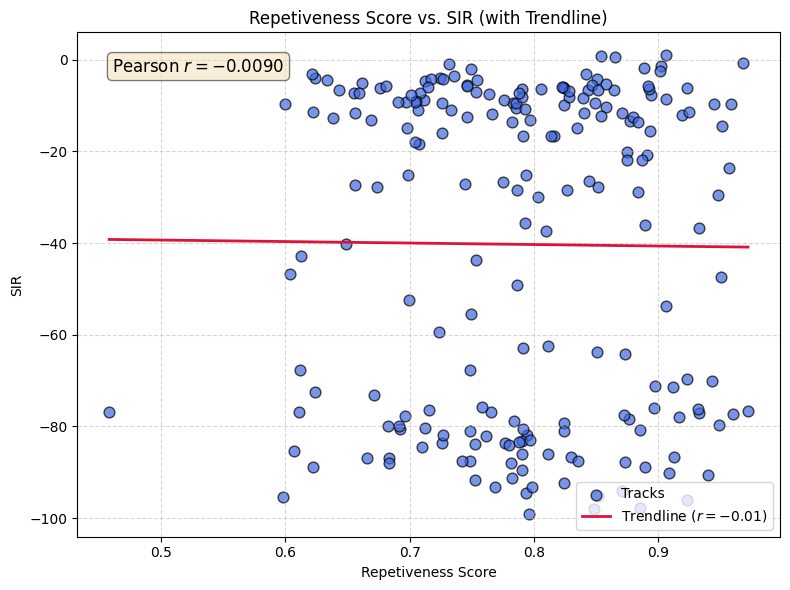

In [8]:
# plot scatter plot of repetiveness score vs SIR
correlation_sir = results_df["repetiveness_score"].corr(results_df["sir"])
print(f"Pearson correlation coefficient (SIR): {correlation_sir:.4f}")

m, b = np.polyfit(results_df["repetiveness_score"], results_df["sir"], 1)

x_line = np.linspace(results_df["repetiveness_score"].min(), results_df["repetiveness_score"].max(), 100)
y_line = m * x_line + b

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    results_df["repetiveness_score"], 
    results_df["sir"], 
    color='royalblue', 
    alpha=0.7, 
    edgecolors='black', 
    s=60, 
    label="Tracks"
)
ax.plot(
    x_line, 
    y_line, 
    color='crimson', 
    linestyle='-', 
    linewidth=2, 
    label=f"Trendline ($r = {correlation_sir:.2f}$)"
)

textstr = f"Pearson $r = {correlation_sir:.4f}$"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12, verticalalignment='top', bbox=props)

ax.set_xlabel("Repetiveness Score")
ax.set_ylabel("SIR")
ax.set_title("Repetiveness Score vs. SIR (with Trendline)")
ax.legend(loc="lower right")

ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("repetiveness_sir_correlation.png")
plt.show()

Pearson correlation coefficient (SAR): -0.0851


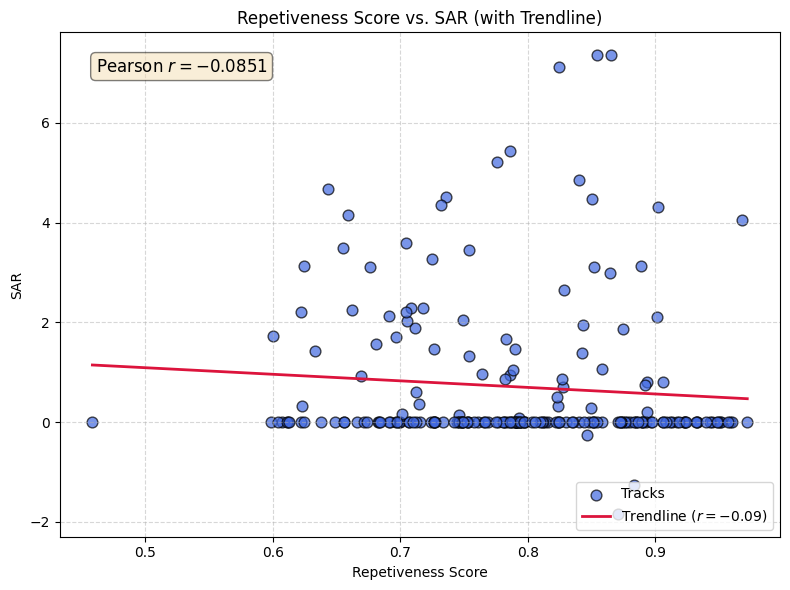

In [9]:
# plot scatter plot of repetiveness score vs SAR
correlation_sar = results_df["repetiveness_score"].corr(results_df["sar"])
print(f"Pearson correlation coefficient (SAR): {correlation_sar:.4f}")

m, b = np.polyfit(results_df["repetiveness_score"], results_df["sar"], 1)

x_line = np.linspace(results_df["repetiveness_score"].min(), results_df["repetiveness_score"].max(), 100)
y_line = m * x_line + b

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    results_df["repetiveness_score"], 
    results_df["sar"], 
    color='royalblue', 
    alpha=0.7, 
    edgecolors='black', 
    s=60, 
    label="Tracks"
)
ax.plot(
    x_line, 
    y_line, 
    color='crimson', 
    linestyle='-', 
    linewidth=2, 
    label=f"Trendline ($r = {correlation_sar:.2f}$)"
)

textstr = f"Pearson $r = {correlation_sar:.4f}$"
props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12, verticalalignment='top', bbox=props)

ax.set_xlabel("Repetiveness Score")
ax.set_ylabel("SAR")
ax.set_title("Repetiveness Score vs. SAR (with Trendline)")
ax.legend(loc="lower right")

ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("repetiveness_sar_correlation.png")
plt.show()